# 02 - Chronological Split & Scaling
Load the dataset from notebook 01, split it Train/Val/Test in time order with a purged embargo gap, and fit the scaler on Train only.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.dataset import ChronologicalSplitter, CausalScaler

DATA_DIR = PROJECT_ROOT / 'data'
SPLIT_DIR = DATA_DIR / 'splits'
SPLIT_DIR.mkdir(exist_ok=True)

In [2]:
dataset = pd.read_parquet(DATA_DIR / 'dataset.parquet')
feature_cols = [c for c in dataset.columns if not c.startswith('fwd_log_return')]
target_col = [c for c in dataset.columns if c.startswith('fwd_log_return')][0]
X, y = dataset[feature_cols], dataset[target_col]
print(X.shape, y.shape, ' target:', target_col)

(4625, 12) (4625,)  target: fwd_log_return_5


## Split configuration
`TEST_FRAC` is fixed at 20% as requested. `SEQ_LEN` (L) and the target horizon (k, baked into the loaded target's name) determine the embargo gap `L + k` purged at each boundary so no window/target straddles two splits.

In [3]:
TRAIN_FRAC = 0.7
TEST_FRAC = 0.2
VAL_FRAC = 1 - TRAIN_FRAC - TEST_FRAC
assert abs(VAL_FRAC - 0.1) < 1e-9

SEQ_LEN = 30  # L, used later by the CNN+GRU sliding window
HORIZON = int(target_col.rsplit('_', 1)[1])
EMBARGO = SEQ_LEN + HORIZON
print(f'train={TRAIN_FRAC} val={VAL_FRAC:.2f} test={TEST_FRAC}  embargo={EMBARGO} rows')

train=0.7 val=0.10 test=0.2  embargo=35 rows


In [4]:
splitter = ChronologicalSplitter(train_frac=TRAIN_FRAC, val_frac=VAL_FRAC, embargo=EMBARGO)
splits = splitter.split(X.index)
print('train:', len(splits.train), splits.train.min(), '->', splits.train.max())
print('val:  ', len(splits.val), splits.val.min(), '->', splits.val.max())
print('test: ', len(splits.test), splits.test.min(), '->', splits.test.max())

train: 3237 2026-09-02 12:05:00-04:00 -> 2026-10-30 15:15:00-04:00
val:   427 2026-11-02 11:45:00-05:00 -> 2026-11-10 09:50:00-05:00
test:  891 2026-11-10 12:50:00-05:00 -> 2026-11-25 15:30:00-05:00


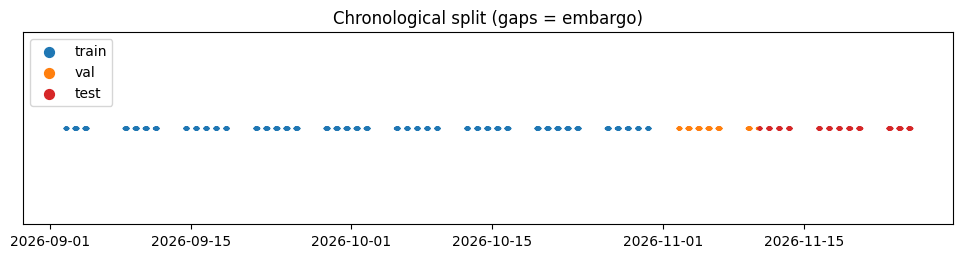

In [5]:
fig, ax = plt.subplots(figsize=(12, 2.5))
for name, idx, color in [('train', splits.train, '#1f77b4'), ('val', splits.val, '#ff7f0e'), ('test', splits.test, '#d62728')]:
    ax.scatter(idx, [0] * len(idx), s=2, color=color, label=name)
ax.set_yticks([])
ax.legend(markerscale=5, loc='upper left')
ax.set_title('Chronological split (gaps = embargo)')
plt.show()

## Scale features (fit on Train only)

In [6]:
SCALER_METHOD = 'standard'  # 'standard' or 'robust'
CLIP_SIGMA = 10.0

scaler = CausalScaler(method=SCALER_METHOD, clip_sigma=CLIP_SIGMA)
scaler.fit(X.loc[splits.train])

X_train = scaler.transform(X.loc[splits.train])
X_val = scaler.transform(X.loc[splits.val])
X_test = scaler.transform(X.loc[splits.test])
y_train, y_val, y_test = y.loc[splits.train], y.loc[splits.val], y.loc[splits.test]
X_train.shape, X_val.shape, X_test.shape

((3237, 12), (427, 12), (891, 12))

## Persist splits for the model/training notebooks

In [7]:
X_train.join(y_train).to_parquet(SPLIT_DIR / 'train.parquet')
X_val.join(y_val).to_parquet(SPLIT_DIR / 'val.parquet')
X_test.join(y_test).to_parquet(SPLIT_DIR / 'test.parquet')
print('Saved train/val/test parquet files to', SPLIT_DIR)

Saved train/val/test parquet files to /Users/user/Desktop/python/quant/CNN-agent/data/splits
